In [1]:
import pandas as pd
import matplotlib.pyplot as mlt
import seaborn as ss
import numpy as ny

In [2]:
t_df = pd.read_csv('/kaggle/input/datasets/muhammadzubairjutt/telco-customer-churn/Telco-Customer-Churn.csv')

In [3]:
df = t_df.copy()

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print(f"There are {len(df.index.unique())} unique customers in {df.shape[0]} ")

There are 7043 unique customers in 7043 


In [6]:
column = df.select_dtypes(include = {'object'}).columns.to_list()
column

['customerID',
 'gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'TotalCharges',
 'Churn']

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
df.nunique()
# Number of unique values in each column

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

In [9]:
feature_to_ignore = ['customerID','tenure','MonthlyCharges','TotalCharges']
col = df.drop(columns = feature_to_ignore)
for c in col:
    y = df[c].value_counts()
    print(f" unique value count of {c}", y)

 unique value count of gender gender
Male      3555
Female    3488
Name: count, dtype: int64
 unique value count of SeniorCitizen SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64
 unique value count of Partner Partner
No     3641
Yes    3402
Name: count, dtype: int64
 unique value count of Dependents Dependents
No     4933
Yes    2110
Name: count, dtype: int64
 unique value count of PhoneService PhoneService
Yes    6361
No      682
Name: count, dtype: int64
 unique value count of MultipleLines MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
 unique value count of InternetService InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
 unique value count of OnlineSecurity OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64
 unique value count of OnlineBackup OnlineBackup
No                    

<span style="font-size: 20px;"> It is a good practice to see the counts of unique values to check 
if a feature contains more values than others. For example in PhoneService
* Yes  has  6361
* No   has   682.
* similarly our target feature is heavily imbalanced.</span>

In [17]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [11]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

<span style="font-size: 20px;"> As result has shown there are no null values. But we are working with
object columns too. sometimes pandas considered Nan or null also as string and miss them in isnull. But these words
aren't helping our model instead create hidden problems in model. Take a look at next cell's result and a hidden problem will become visible. so it is a good pratice to check this</span>

In [12]:
fake_null_patterns = ['nan', 'none', 'null', 'n/a', '', ' ','Nan','Null','None','NAN','NONE','NULL']

# Select all object columns
obj_cols = df.select_dtypes(include=['object']).columns

print(" Scanning Categorical Features for Hidden Traps\n")

for col in obj_cols:
    # 1. Convert everything to lowercase string representation to check text words safely
    # (We fill actual NaNs with empty string temporarily so str methods don't crash)
    series_str = df[col].astype(str).str.strip().str.lower()
    
    # 2. Count how many rows match our fake null patterns
    fake_null_mask = series_str.isin(fake_null_patterns)
    fake_count = fake_null_mask.sum()
    
    # 3. Also check if standard isnull() missed anything because it's an object type
    true_null_count = df[col].isnull().sum()
    
    total_hidden = fake_count - true_null_count
    
    if total_hidden > 0:
        print(f" Column '{col}' has {total_hidden} hidden/fake null rows (blank spaces or text like 'NaN')!")

 Scanning Categorical Features for Hidden Traps

 Column 'TotalCharges' has 11 hidden/fake null rows (blank spaces or text like 'NaN')!


<span style="font-size: 20px;">Now it is proved that **total charges** has 11 null values which were completly
missed in previous case. </span>

<span style = "font-size: 20px;"> However we can remove null values from this column by converting it to numeric. 
However it is best practice to check all the categorical </span>

In [13]:
# Define the fake null patterns
fake_null_patterns = ['', ' ', 'nan', 'none', 'null', 'n/a', 'NaN', 'Null', 'None']

null_rows = df[df['TotalCharges'].astype(str).str.strip().isin(fake_null_patterns) | df['TotalCharges'].isnull()]
null_rows

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


There is a very interesting thing watch tenure and total charges and that's why it is necessary to either drop these rows 
or later fill them with 0.

<span style="font-size: 20px;"> Now since actual null values have been found replace them with actual null </span>

In [14]:

df.replace(['', ' ', 'nan', 'none', 'NULL', 'N/A', 'NaN'], ny.nan, inplace=True)
print(df.isnull().sum())
# and now we can actually either fill them or whatever we want

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [15]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [16]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

<span style="font-size: 20px;"> Now that the matter of Null values is solved we can move forward </span>

In [23]:
df['TotalCharges']=pd.to_numeric(df['TotalCharges'],errors='coerce')

<span style="font-size: 20px;"> **EDA** </span>

**Contract Type** have a strong relation with **Churn**. This column is important to see that which customers are 
more likely to leave.

In [25]:
contract_churn = pd.crosstab(df['Contract'], df['Churn'],normalize='index') * 100
contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


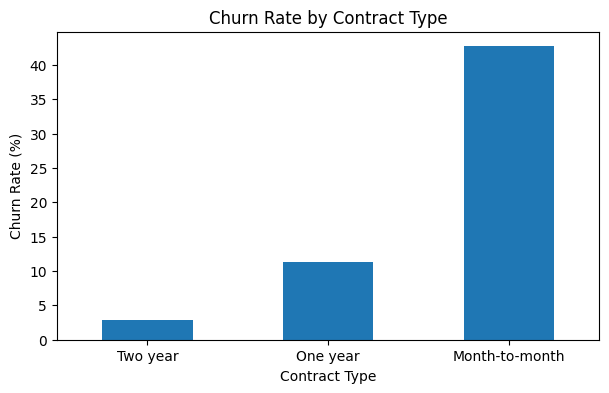

In [26]:
contract_churn['Yes'].sort_values().plot(
    kind="bar",
    figsize=(7, 4)
)

mlt.title("Churn Rate by Contract Type")
mlt.xlabel("Contract Type")
mlt.ylabel("Churn Rate (%)")
mlt.xticks(rotation=0)

mlt.show()

<span style="font-size: 20px;"> **Churn** and **Tenure** </span>

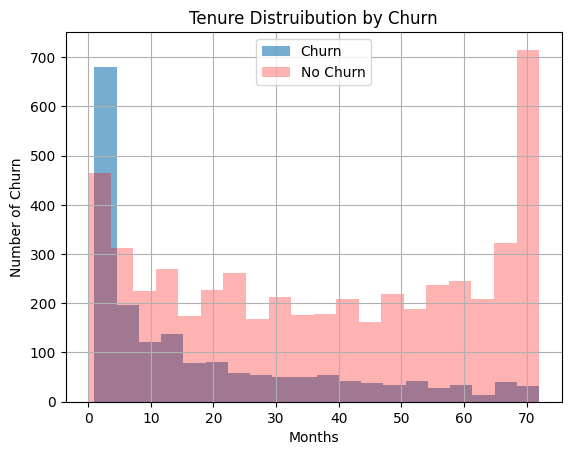

In [27]:
df[df['Churn']== 'Yes']['tenure'].hist(bins=20, alpha = 0.6, label = 'Churn')
df[df['Churn']== 'No']['tenure'].hist(bins=20, alpha = 0.3, label = 'No Churn',color = 'red')
mlt.title('Tenure Distruibution by Churn')
mlt.xlabel('Months')
mlt.ylabel('Number of Churn')
mlt.legend()
mlt.show()

<span style="font-size:20px;">
This shows that the New Customers are more likely to leave but as the time passes they are more likly to stick to the company. </span>


<span style="font-size:20px;">**Churn** and **Monthly Charges**</span>

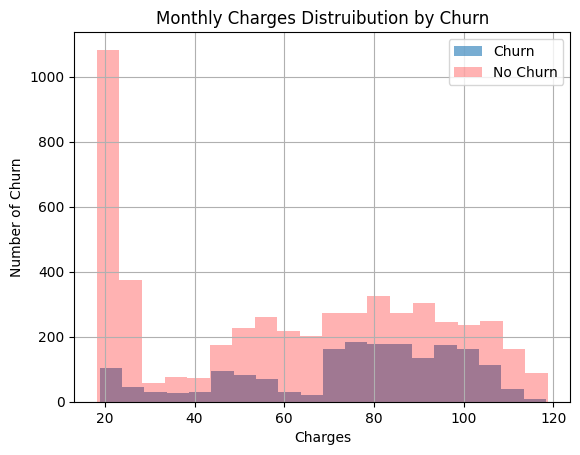

In [28]:
df[df['Churn']== 'Yes']['MonthlyCharges'].hist(bins=20, alpha = 0.6, label = 'Churn')
df[df['Churn']== 'No']['MonthlyCharges'].hist(bins=20, alpha = 0.3, label = 'No Churn',color = 'red')
mlt.title('Monthly Charges Distruibution by Churn')
mlt.xlabel('Charges')
mlt.ylabel('Number of Churn')
mlt.legend()
mlt.show()

<span style="font-size: 20px;">Customers with more Monthly Charges are more likely to Leave.</span>

<span style="font-size:20px;">**Churn** and **Internet Service**</span>

In [29]:
internet_churn = pd.crosstab( df['InternetService'],df['Churn'], normalize = 'index') * 100
internet_churn

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


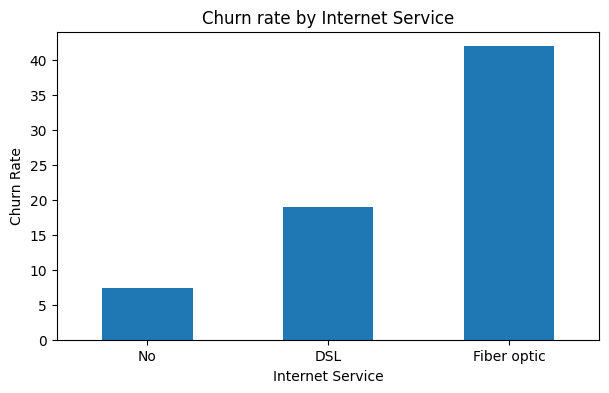

In [30]:
internet_churn['Yes'].sort_values().plot(kind = 'bar', figsize=(7,4))
mlt.title('Churn rate by Internet Service')
mlt.xlabel('Internet Service')
mlt.ylabel('Churn Rate')
mlt.xticks(rotation=0)
mlt.show()

<span style="font-size:20px;">**Churn** and **Online Securite / Tech Support**</span>

In [31]:
for f in ['OnlineSecurity', 'TechSupport']: 
    churn_rate = pd.crosstab(df[f], df['Churn'], normalize='index')*100
    print(f"\n Churn rate by {f} ")
    print(churn_rate)


 Churn rate by OnlineSecurity 
Churn                       No        Yes
OnlineSecurity                           
No                   58.233276  41.766724
No internet service  92.595020   7.404980
Yes                  85.388806  14.611194

 Churn rate by TechSupport 
Churn                       No        Yes
TechSupport                              
No                   58.364526  41.635474
No internet service  92.595020   7.404980
Yes                  84.833659  15.166341


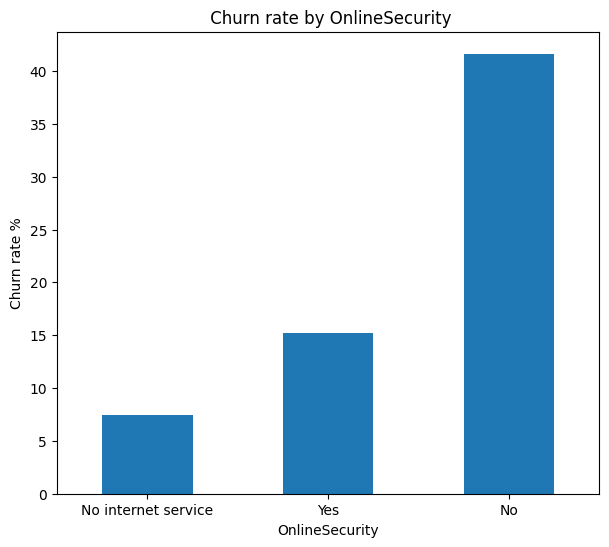

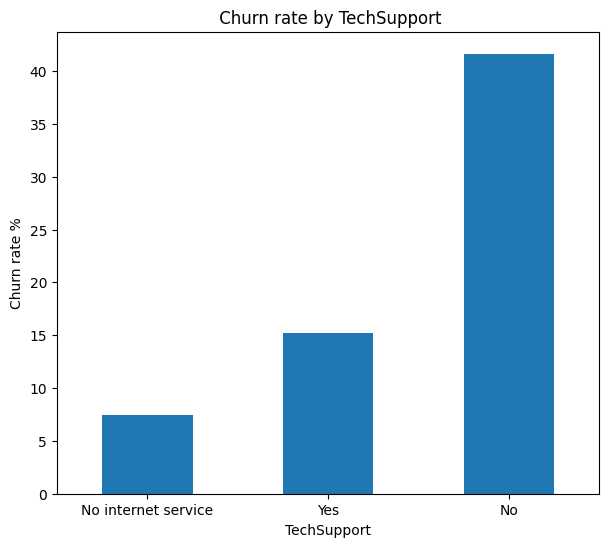

In [32]:
for c in ['OnlineSecurity','TechSupport']: 
    churn_rate['Yes'].sort_values().plot(kind = 'bar', figsize=(7,6))
    mlt.title(f" Churn rate by {c}")
    mlt.xlabel(c)
    mlt.ylabel('Churn rate %')
    mlt.xticks(rotation=0)
    mlt.show()

<span style="font-size: 20px;"> Customers with **No Online Security** and **No Tech Support** are **Leaving** </span>

In [33]:
#mlt.figure(figsize=(10, 8))

#corr = df_encoded.corr()
#ss.heatmap(corr[['Churn']].sort_values(by='Churn', ascending=False), 
 #           annot=True, cmap='coolwarm', vmin=-1, vmax=1)
#mlt.title('Feature Correlation with Churn')
#mlt.show()

**Checking Imabalance of Churn to decide the proper method to solve the problem**

In [34]:
#churn_counts = df_encoded['Churn'].value_counts()
#print("Churn Class Counts")
#print(churn_counts)

#print("-" * 30)

# 2. Get normalized percentages
#churn_percentages = df_encoded['Churn'].value_counts(normalize=True) * 100
#print("Churn Class Percentages")
#print(round(churn_percentages, 2))

# Visualizing 
#mlt.figure(figsize=(6, 4))
#ss.countplot(x='Churn', data=df_encoded, palette='Set2')
#mlt.title('Distribution of Churn Target Class')
#mlt.xlabel('Churn (0 = Retained, 1 = Churned)')
#mlt.ylabel('Number of Customers')
#mlt.show()

<span style =" font-size: 20px;"> Numbers are helpful in explaining the target feature imbalance However visualizing it much more helpful.
Based on results **scale_pos_weight** is best suitable here. </span>

<span style="font-size: 30px;"> **Encoding and Splitting the DATASET** </span>

In [35]:
X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn'].map({'Yes':1, 'No':0})

In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

In [37]:
categorical_features = X_train.select_dtypes(include=['object','category']).columns.tolist()
numerical_features = X_train.select_dtypes(include=['int64','float64']).columns.tolist()

In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [39]:
preprocessor = ColumnTransformer(transformers = [
    (
        'Categorical', OneHotEncoder(handle_unknown = 'ignore'), categorical_features
    )
], remainder = 'passthrough')

In [40]:
# Now back to the track
# Formula : count of negative class/ count of positive class
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
scale_pos_weight_value = negative_count / positive_count

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"Recomended Value: {scale_pos_weight_value: .2f}")

X_train shape: (5634, 19)
X_test shape: (1409, 19)
Recomended Value:  2.77


<span style = "font-size: 15px ;"> This value(2.77) is found to tell xg boost model that for every mistake you make on majority class penalize this(2.77) times
harder when you make a mistake on the minority class. This way model will pay equal attention irrespective of classes' size.
</span>

<span style="font-size: 20px;">**Models**</span>

In [41]:
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

<span style="font-size: 20px;"> **XGBoost** </span>

In [42]:

import xgboost as xgb
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', xgb.XGBClassifier(
        n_estimators=300,
        learning_rate=0.05, 
        max_depth=4, 
        subsample=0.8, 
        colsample_bytree=0.8, 
        gamma=1, 
        min_child_weight=5,
        reg_alpha=0.1, # 
        reg_lambda=1,
        scale_pos_weight=scale_pos_weight_value,
        random_state=42,
        n_jobs=-1,
        eval_metric="auc"
    )
    )
])
xgb_pipeline.fit(X_train, y_train)
y_pred = xgb_pipeline.predict(X_test)
xgb_probs = xgb_pipeline.predict_proba(X_test)[:, 1]

<span style="font-size:20px;"> **RandomForest** </span>

In [46]:
from sklearn.ensemble import RandomForestClassifier

In [47]:
rf_classifier = RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

In [48]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", rf_classifier)
])

rf_pipeline.fit(X_train, y_train)

rf_preds = rf_pipeline.predict(X_test)
rf_probs = rf_pipeline.predict_proba(X_test)[:, 1]

In [50]:
def evaluate_model(y_true, y_pred, y_prob, model_name):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob), # ROC-AUC measures how well the model ranks positive instances above negative ones
                                                  # across different classification thresholds, so it should be calculated using a continuous score,
                                                  # typically the estimated probability of the positive class
        "False Negatives": fn,
        "False Positives": fp
    }

    return results

In [51]:
rf_results = evaluate_model(
    y_test,
    rf_preds,
    rf_probs,
    "Random Forest"
)
rf_results

{'Model': 'Random Forest',
 'Accuracy': 0.7615330021291696,
 'Precision': 0.5358490566037736,
 'Recall': 0.7593582887700535,
 'F1-score': 0.6283185840707964,
 'ROC-AUC': np.float64(0.8412604303908652),
 'False Negatives': np.int64(90),
 'False Positives': np.int64(246)}

In [55]:
xgb_results = evaluate_model(
    y_test,
    y_pred,
    xgb_probs,
    "XGBoost"
)
xgb_results

{'Model': 'XGBoost',
 'Accuracy': 0.7537260468417317,
 'Precision': 0.5241502683363148,
 'Recall': 0.7834224598930482,
 'F1-score': 0.6280814576634512,
 'ROC-AUC': np.float64(0.8416014363584696),
 'False Negatives': np.int64(81),
 'False Positives': np.int64(266)}

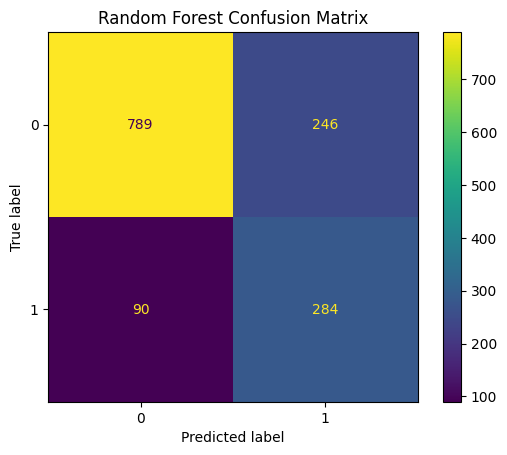

In [57]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_preds
)

mlt.title("Random Forest Confusion Matrix")
mlt.show()

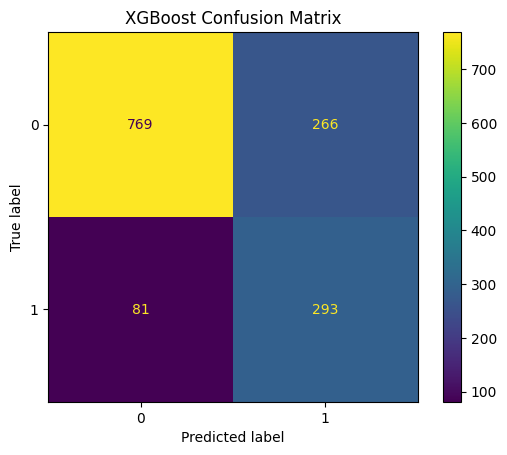

In [58]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

mlt.title("XGBoost Confusion Matrix")
mlt.show()

<span style="font-size: 20px;"> **ROC-AUC Curve** </span>

<Figure size 700x500 with 0 Axes>

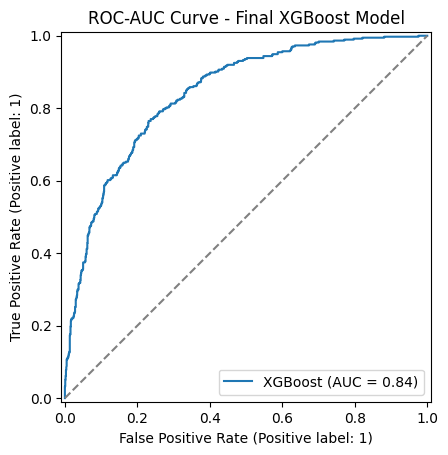

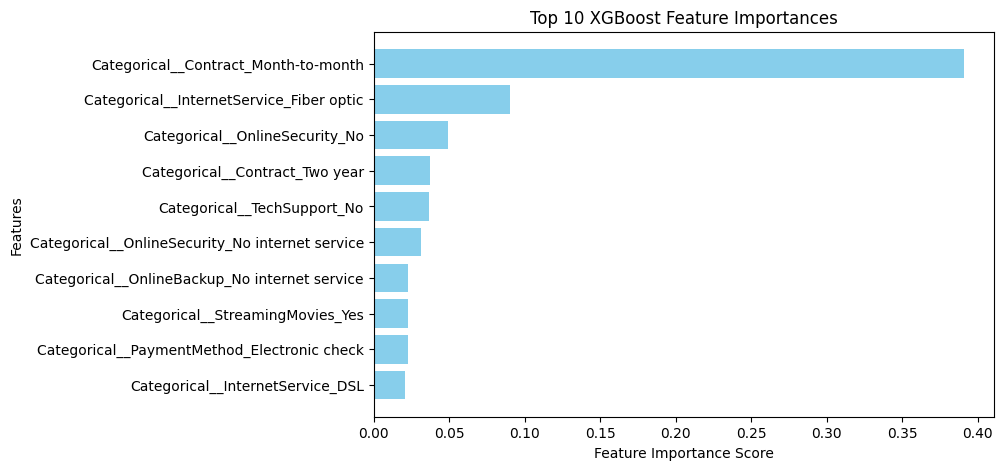

In [59]:
from sklearn.metrics import RocCurveDisplay

mlt.figure(figsize=(7, 5))
RocCurveDisplay.from_estimator(xgb_pipeline, X_test, y_test, name="XGBoost")
mlt.title("ROC-AUC Curve - Final XGBoost Model")
mlt.plot([0, 1], [0, 1], linestyle="--", color="gray")
mlt.show()

# Extract and Plot Top 10 Feature Importances
feature_names = xgb_pipeline.named_steps["preprocessor"].get_feature_names_out()
xgb_model = xgb_pipeline.named_steps["classifier"]

feature_importances = pd.DataFrame({
    "Feature": feature_names, 
    "Importance": xgb_model.feature_importances_
})

# Clean up string labels
feature_importances["Feature"] = (
    feature_importances["Feature"]
    .str.replace("categorical__", "", regex=False)
    .str.replace("remainder__", "", regex=False)
)

top_10 = feature_importances.sort_values(by="Importance", ascending=False).head(10).sort_values(by="Importance")

mlt.figure(figsize=(8, 5))
mlt.barh(top_10["Feature"], top_10["Importance"], color='skyblue')
mlt.title("Top 10 XGBoost Feature Importances")
mlt.xlabel("Feature Importance Score")
mlt.ylabel("Features")
mlt.show()

<span style="font-size: 25px;"> 
**Final Report**
</span>
<span style="font-size: 20px;"> 

1. The Top 10 Feature Importances Bar Chart
This horizontal bar chart illustrates which customer attributes had the biggest impact on the model's decision to predict whether a customer would churn:

Categorical__Contract_Month-to-month is by far the single most dominant factor influencing customer churn. This aligns with your earlier EDA showing that month-to-month subscribers leave at a significantly higher rate than those on one- or two-year contracts.

Categorical__InternetService_Fiber optic is the second strongest predictor, indicating that customers with fiber optic internet have a distinct churn behavior compared to DSL or no internet service.

Other critical indicators include security and support services (OnlineSecurity_No, TechSupport_No), contract length (Contract_Two year), and payment methods (PaymentMethod_Electronic check).

2. The ROC-AUC Curve (Evaluated right before the feature importance plot)
The Receiver Operating Characteristic (ROC) curve evaluates how effectively your XGBoost model separates customers who churned from those who stayed across all possible classification thresholds.

Achieving a high ROC-AUC score (~0.84) indicates that your model has strong discriminatory power and performs exceptionally well at ranking true churners above retained customers, comfortably clearing your evaluation benchmarks.
</span>

In [60]:
from sklearn.metrics import roc_auc_score

# 1. Get training probabilities
train_probs = xgb_pipeline.predict_proba(X_train)[:, 1]
train_auc = roc_auc_score(y_train, train_probs)

# 2. Get test probabilities (you already have xgb_probs)
test_auc = roc_auc_score(y_test, xgb_probs)

print(f"Training ROC-AUC: {train_auc:.4f}")
print(f"Test ROC-AUC:     {test_auc:.4f}")

Training ROC-AUC: 0.9062
Test ROC-AUC:     0.8416
